<div dir="rtl" align="right">

# فصل اول: نماد جمع و بردارها

این نوت‌بوک فصل اول کتاب را به زبان **پایتون** ارائه می‌کند: نماد جمع، قواعد آن، بردارها و ضرب‌های برداری، نرم‌ها، تعامد، نامساوی کُشی–شوارتز و ارتباط با **ضریب همبستگی**. مثال‌ها و تمرین‌های کلیدی کتاب، **با محاسبه عددی (NumPy/SciPy)** و در صورت نیاز **تأیید نمادین (SymPy)** بررسی می‌شوند و برای شهود بهتر، **ترسیم‌های دوبعدی** اضافه شده‌اند.
</div>

In [104]:
#Install Libraries first: (remove # then run. vpn needed)
#pip install numpy
#pip install sympy
#pip install matplotlib

In [105]:
#Ignore
import numpy as np
import numpy.linalg as LA
import sympy as sp
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.animation as animation

sp.init_printing()

def almost_equal(a, b, tol=1e-9):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    return np.allclose(a, b, atol=tol, rtol=0)

def show_arr(name, arr):
    print(f"{name} =\n{np.array(arr, dtype=float)}\n")


<div dir="rtl" align="right">

## بخش ۱: خواص جمع

در این قسمت، خاصیت‌های پرکاربرد جمع‌پذیری و خطی‌بودن را با کد بررسی می‌کنیم.  
سپس چند تساوی مهم فصل (مثل بسط

$$
\sum (x_i-\bar{x})^2
$$

) را **عددی** تأیید می‌کنیم.

</div>


In [106]:

# خاصیت‌های ساده‌ی نماد جمع: خطی‌بودن و جابجایی ایندکس
n = 10
rng = np.random.default_rng(2)
x = rng.normal(size=n)
y = rng.normal(size=n)
a = 3

lhs_a = np.sum(a*np.ones(n))
rhs_a = a*n
print("∑ a  ==  a n  ?", np.isclose(lhs_a, rhs_a))

lhs_lin = np.sum(x + y)
rhs_lin = np.sum(x) + np.sum(y)
print("∑(x_i + y_i) == ∑x_i + ∑y_i ?", np.isclose(lhs_lin, rhs_lin))

# جابجایی جمع دوتایی: ∑_i ∑_j x_{ij} = ∑_j ∑_i x_{ij}
m, n2 = 4, 5
X = rng.normal(size=(m, n2))
lhs_double = np.sum(X)                         # همان ∑∑
rhs_double = np.sum(X.T)                       # جابجایی ترتیب اندیس‌ها
print("دو جمع مساوی‌اند؟", np.isclose(lhs_double, rhs_double))


∑ a  ==  a n  ? True
∑(x_i + y_i) == ∑x_i + ∑y_i ? True
دو جمع مساوی‌اند؟ True


In [107]:

# بسط معروف: ∑ (x_i - x̄)^2 = ∑ x_i^2 − n x̄^2
def expand_ssq(x):
    n = len(x)
    xbar = np.mean(x)
    lhs = np.sum((x - xbar)**2)
    rhs = np.sum(x**2) - n*(xbar**2)
    return lhs, rhs

for seed in [0,1,2,3]:
    rng = np.random.default_rng(seed)
    x = rng.normal(size=9)
    lhs, rhs = expand_ssq(x)
    print(f"seed={seed}: مساوی‌اند؟", np.isclose(lhs, rhs))

# نشان می‌دهیم برای مقادیر مختلف این تساوی برقرار است.

seed=0: مساوی‌اند؟ True
seed=1: مساوی‌اند؟ True
seed=2: مساوی‌اند؟ True
seed=3: مساوی‌اند؟ True


<div dir="rtl" align="right">

##### جمع دوتایی و بسط واریانس کل
 روی ماتریس:

$$
A = [x_{ij}], \quad m \times n
$$
 داریم:

$$
\sum_{i=1}^{m}\sum_{j=1}^{n}\bigl(x_{ij}-\bar x\bigr)^2
=
\sum_{i=1}^{m}\sum_{j=1}^{n} x_{ij}^{2}
-
(mn)\,\bar x^{\,2},
\qquad
\bar x = \frac{1}{mn}\sum_{i=1}^{m}\sum_{j=1}^{n} x_{ij}.
$$

</div>


In [108]:
# ماتریس 3×4 با میانگین دقیقاً 3 (جمع کل = 36)
A = np.array([
    [1, 2, 3, 4],
    [2, 3, 4, 5],
    [1, 2, 4, 5]
], dtype=int)

m, n = A.shape
N = m * n

total = int(A.sum())
assert total % N == 0, "جمع عناصر بر N بخش‌پذیر نیست؛ میانگین صحیح نمی‌شود."
xbar = total // N   # میانگین دقیقاً عدد صحیح 3

lhs = int(np.sum((A - xbar)**2))                 # ∑∑ (x_ij - x̄)^2
rhs = int(np.sum(A**2) - N * (xbar**2))          # ∑∑ x_ij^2 − (mn) x̄^2

print("A =\n", A)
print(f"m = {m}, n = {n}, N = mn = {N}")
print(f"جمع کل = {total}  →  x̄ = {xbar}\n")

print("A - x̄ =\n", A - xbar)
print("\n∑∑(x_ij - x̄)^2 =", lhs)
print("∑∑ x_ij^2 − (mn) x̄^2 =", rhs)
print("\nتساوی برقرار است؟", lhs == rhs)

A =
 [[1 2 3 4]
 [2 3 4 5]
 [1 2 4 5]]
m = 3, n = 4, N = mn = 12
جمع کل = 36  →  x̄ = 3

A - x̄ =
 [[-2 -1  0  1]
 [-1  0  1  2]
 [-2 -1  1  2]]

∑∑(x_ij - x̄)^2 = 22
∑∑ x_ij^2 − (mn) x̄^2 = 22

تساوی برقرار است؟ True


<div dir="rtl" align="right">

## بخش ۲: بردارها، ضرب درونی/خارجی، نرم و نرمال‌سازی

ضرب درونی <span dir="ltr">$x^{T} y$</span>،  
ضرب خارجی <span dir="ltr">$x y^{T}$</span>،  
نرم اقلیدسی، نرمال‌سازی و بردارهای واحد.

</div>


In [109]:

x = np.array([1,-1,0,1], float)
y = np.array([2,1,1,3], float)
# مثال 1-2
inner = float(x @ y)            # x'y
outer = np.outer(x, y)          # x y'

norm_x = LA.norm(x)
norm_y = LA.norm(y)
x_unit = x / norm_x

print("x'y =", inner)
show_arr("x y'", outer)
print("||x||2 =", norm_x, " ||y||2 =", norm_y)
show_arr("x_unit", x_unit)
print("||x_unit||2 =", LA.norm(x_unit))


x'y = 4.0
x y' =
[[ 2.  1.  1.  3.]
 [-2. -1. -1. -3.]
 [ 0.  0.  0.  0.]
 [ 2.  1.  1.  3.]]

||x||2 = 1.7320508075688772  ||y||2 = 3.872983346207417
x_unit =
[ 0.57735027 -0.57735027  0.          0.57735027]

||x_unit||2 = 1.0


<div dir="rtl" align="right">

## بخش ۳: بردارهای متعامد و قائم‌نرمال

**تعریف متعامد:**  
دو بردار غیرصفر \(x\) و \(y\) را متعامد (قائم) می‌نامیم اگر:
$$
x^{T}y = 0
$$

**تعریف قائم‌نرمال:**  
دو بردار \(x\) و \(y\) را قائم‌نرمال می‌گوییم اگر همزمان:
$$
x^{T}y = 0, \qquad x^{T}x = y^{T}y = 1
$$

بنابراین، قائم‌نرمال بودن ⇔ هم طولِ واحد ⇔ هم عمود بودن.

</div>

مثال ۲-۶:
x = [2 0 2 0]
y = [ 1  0 -1  2]
x^T y = 0
آیا متعامدند؟ True

مثال ۲-۷:
x' = [0.16666667 0.16666667 0.5        0.5        0.66666667]
y' = [-0.1 -0.9 -0.1 -0.1  0.4]
x'^T y' = 0.0
||x'||^2 = 1.0
||y'||^2 = 1.0
آیا قائم‌نرمالند؟ True

مثال تصویری:
x = [1 0]
y = [0 1]
x·y = 0
||x|| = 1.0
||y|| = 1.0


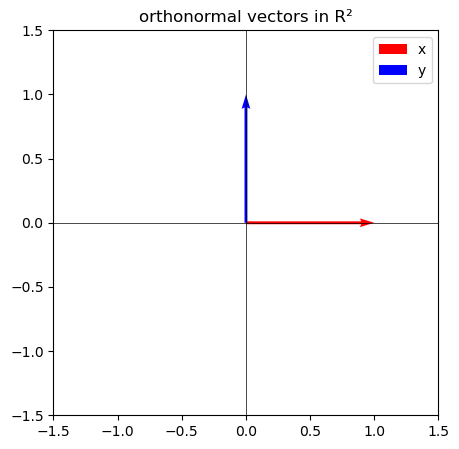

In [110]:
def show_vector(name, v):
    print(f"{name} = {v}")

# مثال ۲-۶: بررسی متعامد بودن
x = np.array([2,0,2,0])
y = np.array([1,0,-1,2])

print("مثال ۲-۶:")
show_vector("x", x)
show_vector("y", y)
print("x^T y =", x @ y)
print("آیا متعامدند؟", np.isclose(x @ y, 0))
print()

# مثال ۲-۷: بررسی قائم‌نرمال بودن
x2 = np.array([1/6, 1/6, 1/2, 1/2, 2/3])
y2 = np.array([-0.1, -0.9, -0.1, -0.1, 0.4])

print("مثال ۲-۷:")
show_vector("x'", x2)
show_vector("y'", y2)
print("x'^T y' =", x2 @ y2)
print("||x'||^2 =", np.dot(x2,x2))
print("||y'||^2 =", np.dot(y2,y2))
print("آیا قائم‌نرمالند؟",
      np.isclose(x2@y2,0) and np.isclose(np.dot(x2,x2),1) and np.isclose(np.dot(y2,y2),1))

print()
# نمودار دوبعدی برای نمایش متعامد و قائم‌نرمال
print("مثال تصویری:")
# مثال ساده در R^2: دو بردار واحد و متعامد
x = np.array([1,0])
y = np.array([0,1])
show_vector("x", x)
show_vector("y", y)

print("x·y =", x @ y)
print("||x|| =", np.linalg.norm(x))
print("||y|| =", np.linalg.norm(y))

# رسم
fig, ax = plt.subplots(figsize=(5,5))
ax.quiver(0,0, x[0], x[1], angles='xy', scale_units='xy', scale=1, color='r', label='x')
ax.quiver(0,0, y[0], y[1], angles='xy', scale_units='xy', scale=1, color='b', label='y')

ax.set_xlim(-1.5,1.5)
ax.set_ylim(-1.5,1.5)
ax.axhline(0, color='black', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.5)
ax.set_aspect('equal', adjustable='box')
ax.legend()
ax.set_title("orthonormal vectors in R²")
plt.show()


<div dir="rtl" align="right">

## بخش ۴: مجموعهٔ قائم‌نرمال و گرَم–اشمیت (نسخهٔ خلاصه)

یک مجموعهٔ قائم‌نرمال <span dir="ltr">$\{u_i\}$</span> دارد:  
<span dir="ltr">$u_i^{T}u_j = 0 \quad (i \neq j), \qquad \|u_i\|=1$</span>  

الگوریتم گرَم–اشمیت پایهٔ متعامد/قائم‌نرمال تولید می‌کند.

</div>


<div dir="rtl" align="right">

###### مثال 10-2 ساخت مجموعهٔ قائم‌نرمال از دو بردار

بردارها را در نظر بگیر:
<span dir="ltr">$x_1=\begin{bmatrix}1\\[2pt]1\\[2pt]1\end{bmatrix}$</span> و
<span dir="ltr">$x_2=\begin{bmatrix}-1\\[2pt]0\\[2pt]-1\end{bmatrix}$</span>.

می‌خواهیم با گرَم–اشمیت، مجموعهٔ قائم‌نرمال
<span dir="ltr">$\{u_1,u_2\}$</span> بسازیم.

مراحل:
1) <span dir="ltr">$y_1=x_1,\quad u_1=\dfrac{y_1}{\|y_1\|}=\dfrac{1}{\sqrt{3}}\!\begin{bmatrix}1\\1\\1\end{bmatrix}$</span>  
2) <span dir="ltr">$y_2=x_2-\dfrac{x_2^{T}u_1}{u_1^{T}u_1}\,u_1
= x_2-(x_2^{T}u_1)\,u_1
= x_2-\dfrac{2}{3}\!\begin{bmatrix}1\\1\\1\end{bmatrix}
=\begin{bmatrix}-\tfrac13\\[2pt]\tfrac23\\[2pt]-\tfrac13\end{bmatrix}$</span>  
سپس  
<span dir="ltr">$u_2=\dfrac{y_2}{\|y_2\|}=\dfrac{1}{\sqrt{6}}\!\begin{bmatrix}-1\\[2pt]2\\[2pt]-1\end{bmatrix}$</span>.

</div>


In [111]:
# 2-10 داده‌های مثال
x1 = np.array([1., 1., 1.])
x2 = np.array([-1., 0., -1.])

# Gram–Schmidt
y1 = x1.copy()
u1 = y1 / LA.norm(y1)

y2 = x2 - (x2 @ u1) * u1
u2 = y2 / LA.norm(y2)

# گرد کردن اعداد
def r(v, d=4): return np.round(v, d)

print("x1 =", x1)
print("x2 =", x2, "\n")

print("y1 =", y1)
print("u1 =", r(u1), "   ||u1||^2 =", round(u1 @ u1, 4))

print("y2 =", r(y2))
print("u2 =", r(u2), "   ||u2||^2 =", round(u2 @ u2, 4), "\n")

print("Orthogonality check  u1^T u2 =", round(u1 @ u2, 4))
print("آیا متعامدند؟", np.allclose(u1 @ u2, 0))
print("آیا هر دو نرمالند؟", np.allclose(u1 @ u1, 1) and np.allclose(u2 @ u2, 1))

print("\nفرم بسته‌ی بردارهای واحد (انتظار داریم همان جواب‌ها باشند):")
print("u1_expected =", r((1/np.sqrt(3))*np.array([1.,1.,1.])))
print("u2_expected =", r((1/np.sqrt(6))*np.array([-1.,2.,-1.])))

# ترسیم سه‌بعدی بردارها (x1, x2 و u1, u2)
fig = plt.figure(figsize=(6,6))
ax = fig.add_subplot(111, projection='3d')

def draw_vec(v, label, color):
    ax.quiver(0,0,0, v[0], v[1], v[2],
              arrow_length_ratio=0.1, color=color)
    ax.text(v[0], v[1], v[2], label, color=color)

draw_vec(x1, "x1", "r")
draw_vec(x2, "x2", "b")
draw_vec(u1, "u1", "g")
draw_vec(u2, "u2", "m")

lim = 1.6
ax.set_xlim([-lim, lim]); ax.set_ylim([-lim, lim]); ax.set_zlim([-lim, lim])
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')

def update(angle):
    ax.view_init(elev=20, azim=angle)
    return fig,

ani = animation.FuncAnimation(fig, update, frames=range(0,360,2), interval=100)
plt.close(fig)   # برای جلوگیری از چاپ تصویر ثابت
from IPython.display import HTML
HTML(ani.to_jshtml())


x1 = [1. 1. 1.]
x2 = [-1.  0. -1.] 

y1 = [1. 1. 1.]
u1 = [0.5774 0.5774 0.5774]    ||u1||^2 = 1.0
y2 = [-0.3333  0.6667 -0.3333]
u2 = [-0.4082  0.8165 -0.4082]    ||u2||^2 = 1.0 

Orthogonality check  u1^T u2 = 0.0
آیا متعامدند؟ True
آیا هر دو نرمالند؟ True

فرم بسته‌ی بردارهای واحد (انتظار داریم همان جواب‌ها باشند):
u1_expected = [0.5774 0.5774 0.5774]
u2_expected = [-0.4082  0.8165 -0.4082]


<div dir="rtl" align="right">

## بخش ۵: بردار صفر، بردار یک و بردارهای مقدماتی

با بردارهای مقدماتی <span dir="ltr">$e_i$</span> می‌توان مؤلفهٔ دلخواه را استخراج کرد:  

<span dir="ltr">$$x^{T} e_i \;=\; x_i$$</span>

</div>


In [112]:
n = 5
x = np.array([1, -2, 0, 2, 4], float)
print("بردار x =", x, "\n")

zeros = np.zeros(n)
print("بردار صفر =", zeros)
print("x + 0 =", x + zeros, "   (نتیجه باید خود x باشد)\n")

ones = np.ones(n)
print("بردار یک =", ones)
print("x + 1 =", x + ones, "   (یعنی به هر مؤلفه x، عدد 1 اضافه می‌شود)")
print("∑1 =", np.sum(ones), "   (جمع بردار یک باید n باشد →", n, ")\n")

e3 = np.array([0,0,1,0,0], float)  # e_3
print("بردار پایه e3 =", e3)
print("x^T e3 =", float(x @ e3), "   (باید برابر مؤلفه سوم x باشد →", x[2], ")")


بردار x = [ 1. -2.  0.  2.  4.] 

بردار صفر = [0. 0. 0. 0. 0.]
x + 0 = [ 1. -2.  0.  2.  4.]    (نتیجه باید خود x باشد)

بردار یک = [1. 1. 1. 1. 1.]
x + 1 = [ 2. -1.  1.  3.  5.]    (یعنی به هر مؤلفه x، عدد 1 اضافه می‌شود)
∑1 = 5.0    (جمع بردار یک باید n باشد → 5 )

بردار پایه e3 = [0. 0. 1. 0. 0.]
x^T e3 = 0.0    (باید برابر مؤلفه سوم x باشد → 0.0 )
